# Get started with ChakraTS-OS-10M

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yhatlabs/yhatlabs-cookbook/blob/main/getting-started/chakrats-os-10m.ipynb)

ChakraTS-OS-10M is our open forecasting model. It runs on your own machine with the `yhatmodels` library, a laptop CPU
is enough, and your data never leaves it. In this notebook you forecast a week of electricity demand in Texas, check the
model on past days, give it what you know about the future, and fine-tune it on your series.

The first download asks you to accept the model license once, with a free yhatlabs.com account. In Colab, add the token
from https://yhatlabs.com/models/license as the secret `YHAT_MODELS_TOKEN`.

During early access the weights are gated: request access on the
[model page](https://huggingface.co/yhatlabs/ChakraTS-OS-10M), then sign in with `hf auth login` (in Colab, add your
Hugging Face token as the secret `HF_TOKEN`).

In [1]:
%pip install -q -U "yhatmodels[plot]" "datasets>=4"

In [2]:
import os
try:  # in Colab: the license token and the Hugging Face token from Secrets
    from google.colab import userdata
    for name in ("YHAT_MODELS_TOKEN", "HF_TOKEN"):
        try:
            os.environ.setdefault(name, userdata.get(name))
        except Exception:
            pass
except ImportError:
    pass  # on your own computer the first download opens your browser instead

from yhatmodels import ChakraTS

model = ChakraTS.from_pretrained("ChakraTS-OS-10M")  # downloads 42 MB once

## 1. Load some history

One row per series and hour: the series id, the timestamp and the value.

In [3]:
import datasets
import pandas as pd

ercot = datasets.load_dataset("autogluon/fev_datasets", "ercot_1H", split="train")
df = pd.concat(pd.DataFrame({"unique_id": r["id"], "ds": r["timestamp"], "y": r["target"]}) for r in ercot)
df = df[df["ds"] > df["ds"].max() - pd.Timedelta(weeks=8)].reset_index(drop=True)  # the last 8 weeks of every region

cutoff = df["ds"].max() - pd.Timedelta(hours=168)
history, actual = df[df["ds"] <= cutoff], df[df["ds"] > cutoff]  # forecast the last week, then compare with what happened
print(f"{df['unique_id'].nunique()} regions, hourly, {history['ds'].min():%Y-%m-%d} to {history['ds'].max():%Y-%m-%d}")

8 regions, hourly, 2021-07-07 to 2021-08-25


## 2. Forecast a week ahead

`level=[80, 95]` asks for two ranges around the median: the actual value should fall inside the 80% range about 80% of the time.

In [4]:
fc_df = model.forecast(history, h=168, level=[80, 95])
fc_df.head()

,unique_id,ds,q2.5,q10,median,q90,q97.5
0,COAST,2021-08-25 01:00:00,14957.949219,15039.634766,15141.778320,15250.521484,15318.001953
1,COAST,2021-08-25 02:00:00,14126.802734,14274.020508,14434.240234,14593.691406,14703.553711
2,COAST,2021-08-25 03:00:00,13490.010742,13702.784180,13918.308594,14123.773438,14272.636719
3,COAST,2021-08-25 04:00:00,13104.044922,13369.240234,13628.619141,13870.383789,14057.155273
4,COAST,2021-08-25 05:00:00,12924.685547,13265.325195,13577.443359,13849.718750,14068.847656


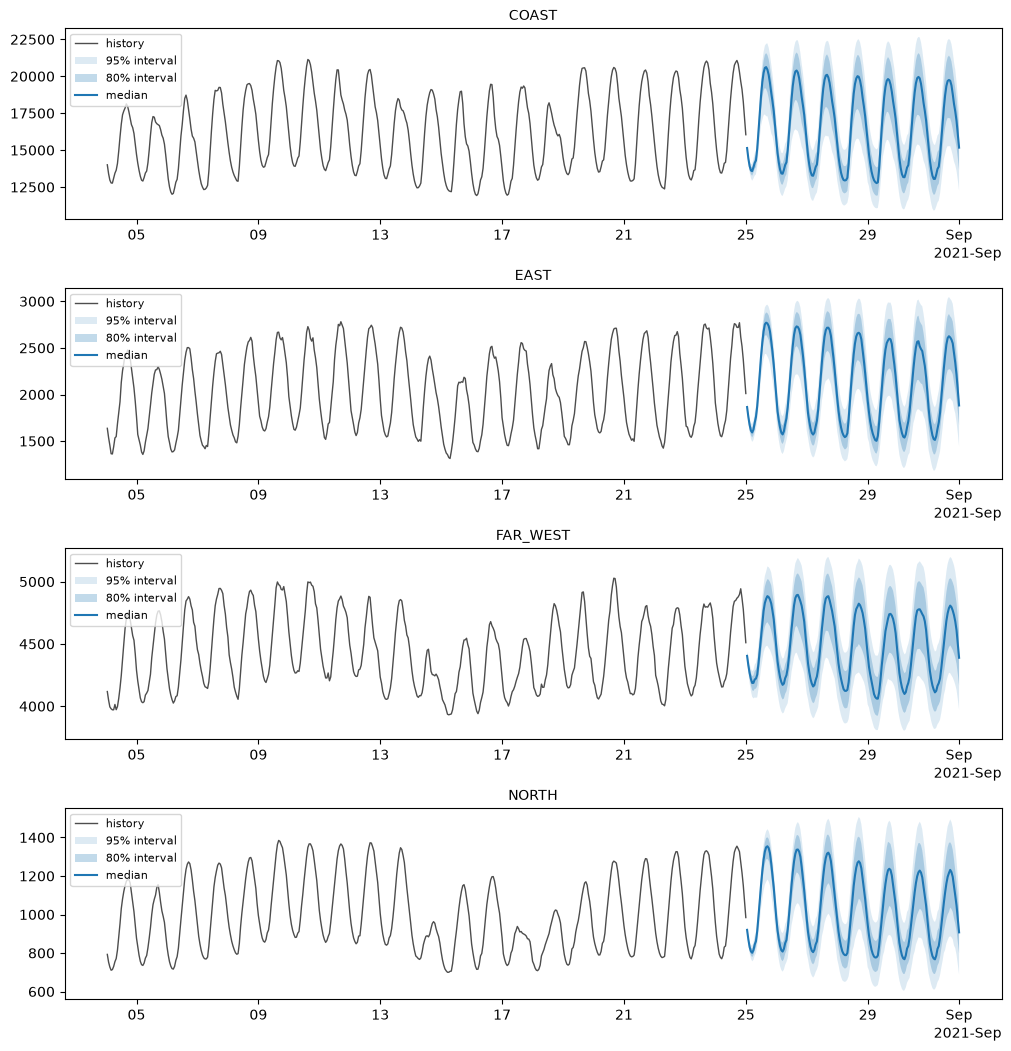

In [5]:
from yhatmodels import plot_forecast

plot_forecast(fc_df, history=history);

Compare with what actually happened that week:

In [6]:
scored = fc_df.merge(actual, on=["unique_id", "ds"])
error = ((scored["median"] - scored["y"]).abs() / scored["y"]).mean()
inside = ((scored["y"] >= scored["q10"]) & (scored["y"] <= scored["q90"])).mean()
print(f"The median is off by {error:.1%} on average, and {inside:.0%} of the actual values fall inside the 80% range.")

The median is off by 3.6% on average, and 95% of the actual values fall inside the 80% range.


## 3. Check it on your own history

`evaluate` goes back to several points in the past, forecasts from each, and scores the forecasts against what happened, next to a simple seasonal forecast (the same hour a day earlier). `skill_mase` above 0 means the model beats it.

In [7]:
res = model.evaluate(df, h=24, windows=7)  # each of the last 7 days, 24 hours ahead
res.summary

,mase,sql,wql,mae,rmse,coverage@0.8,skill_mase,skill_sql,skill_wql,skill_mae,skill_rmse
model,,,,,,,,,,,
ChakraTS-OS-10M,0.584428,0.460489,0.019949,201.201530,261.352486,0.852679,0.337307,0.391512,0.391512,0.337307,0.310848
seasonal_naive,0.877858,0.729316,0.032025,314.501886,379.102959,0.848214,0.000000,0.000000,0.000000,0.000000,0.000000


## 4. Use what you know about the future

Electricity prices depend on demand and wind, and grid operators publish forecasts of both a day ahead. Give those columns to the model as `known` inputs: their values over the next 24 hours sit in the same table.

In [8]:
np_ = datasets.load_dataset("autogluon/fev_datasets", "epf_np", split="train")[0]
prices = pd.DataFrame({"unique_id": "Nord Pool", "ds": np_["timestamp"], "y": np_["target"],
                       "load_forecast": np_["Grid load forecast"], "wind_forecast": np_["Wind power forecast"]})
prices = prices.iloc[-24 * 7 * 12:].reset_index(drop=True)  # the last 12 weeks, hourly
prices.tail(3)

,unique_id,ds,y,load_forecast,wind_forecast
2013,Nord Pool,2018-12-24 21:00:00,49.090000,51488.0,2919.0
2014,Nord Pool,2018-12-24 22:00:00,49.020000,50928.0,3119.0
2015,Nord Pool,2018-12-24 23:00:00,48.099998,49889.0,3306.0


In [9]:
history_only = model.evaluate(prices[["unique_id", "ds", "y"]], h=24, windows=7)
with_forecasts = model.evaluate(prices, h=24, windows=7, known=["load_forecast", "wind_forecast"])
pd.DataFrame({"history only": history_only.summary.iloc[0][["mase", "wql"]],
              "with load and wind forecasts": with_forecasts.summary.iloc[0][["mase", "wql"]]})

,history only,with load and wind forecasts
mase,0.810974,0.531924
wql,0.045799,0.029777


## 5. Fine-tune on your series

`tune` adapts the model to your history, on your machine. It holds out the last `h` steps, and keeps the tuned model only if it beats the original there.

In [10]:
tuned = model.tune(history, h=24)
tuned.report

{'used': True,
 'holdout': {'h': 24,
  'series': 8,
  'pretrained': {'loss': 0.1569, 'wape': 0.0175},
  'tuned': {'loss': 0.1486, 'wape': 0.0171}},
 'steps': 300,
 'steps_max': 300,
 'rank': 8,
 'min_gain': 0.02,
 'seconds': 29.3}

In [11]:
folder = tuned.save("my-tuned")  # weights, config and the license files
print(f"saved to {folder}; load it with ChakraTS.from_pretrained('my-tuned')")

saved to my-tuned; load it with ChakraTS.from_pretrained('my-tuned')


*Data: hourly electricity demand of the eight ERCOT weather zones in Texas (public ERCOT data, via [neuralprophet-data](https://github.com/ourownstory/neuralprophet-data)); Nord Pool day-ahead prices with the published load and wind forecasts, from [Lago et al. (2021)](https://zenodo.org/records/4624805) (CC BY 4.0). Both are loaded from [autogluon/fev_datasets](https://huggingface.co/datasets/autogluon/fev_datasets).*

## Next steps

- [Docs](https://yhatlabs.com/models/docs/open-models): every option of `forecast`, `evaluate` and `tune`
- [Benchmarks](../benchmarks): our leaderboard results and how to reproduce them
- For production use, ChakraTS through the API: [get started](chakrats.ipynb)